### 1. Gerekli kütüphaneler

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Grafiklerin daha düzenli görünmesi için
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)


### 2. Excel dosyasını okuma

In [17]:
dosya = "degerlendirme_veri.xlsx"

# Excel sayfalarını kontrol edelim
excel = pd.ExcelFile(dosya)
print("Excel sayfaları:", excel.sheet_names)

# Gerekli sayfaları okuyalım
ogrenciler = pd.read_excel(dosya, sheet_name="Ogrenciler")
sinav = pd.read_excel(dosya, sheet_name="Gunluk_Sinav")
degerlendirme = pd.read_excel(dosya, sheet_name="Gunluk_Degerlendirme")

print("Öğrenciler:", ogrenciler.shape)
print("Sınav:", sinav.shape)
print("Değerlendirme:", degerlendirme.shape)

display(ogrenciler.head())
display(sinav.head())
display(degerlendirme.head())


Excel sayfaları: ['Rehber', 'Ogrenciler', 'Gunluk_Sinav', 'Gunluk_Degerlendirme']
Öğrenciler: (50, 3)
Sınav: (650, 3)
Değerlendirme: (650, 3)


,No,Ad Soyad,Grup
0,1,Ahmet Yıldırım,A
1,2,Mehmet Demir,B
2,3,Ayşe Kaya,C
3,4,Fatma Şahin,A
4,5,Hasan Arslan,B


,Tarih,No,Not
0,2022-10-10,1,50.0
1,2022-10-10,2,100.0
2,2022-10-10,3,100.0
3,2022-10-10,4,100.0
4,2022-10-10,5,100.0


,Tarih,No,Puan
0,2022-10-10,1,3
1,2022-10-10,2,6
2,2022-10-10,3,6
3,2022-10-10,4,6
4,2022-10-10,5,6


### 3. Veri kontrolü ve eksik değerler

In [18]:
print("Öğrenciler tablosundaki eksik değerler:")
display(ogrenciler.isnull().sum().to_frame("Eksik değer"))

print("Sınav tablosundaki eksik değerler:")
display(sinav.isnull().sum().to_frame("Eksik değer"))

print("Değerlendirme tablosundaki eksik değerler:")
display(degerlendirme.isnull().sum().to_frame("Eksik değer"))

# Tarih sütunlarını tarih tipine dönüştürelim
sinav["Tarih"] = pd.to_datetime(sinav["Tarih"])
degerlendirme["Tarih"] = pd.to_datetime(degerlendirme["Tarih"])

# Aynı tarih ve öğrenci için birden fazla kayıt var mı?
print("Sınavda yinelenen kayıt:", sinav.duplicated(subset=["Tarih", "No"]).sum())
print("Değerlendirmede yinelenen kayıt:", degerlendirme.duplicated(subset=["Tarih", "No"]).sum())


Öğrenciler tablosundaki eksik değerler:


,Eksik değer
No,0
Ad Soyad,0
Grup,0


Sınav tablosundaki eksik değerler:


,Eksik değer
Tarih,0
No,0
Not,0


Değerlendirme tablosundaki eksik değerler:


,Eksik değer
Tarih,0
No,0
Puan,0


Sınavda yinelenen kayıt: 0
Değerlendirmede yinelenen kayıt: 0


Gruplara göre öğrenci sayıları:


,Öğrenci Sayısı
Grup,
A,17
B,17
C,16


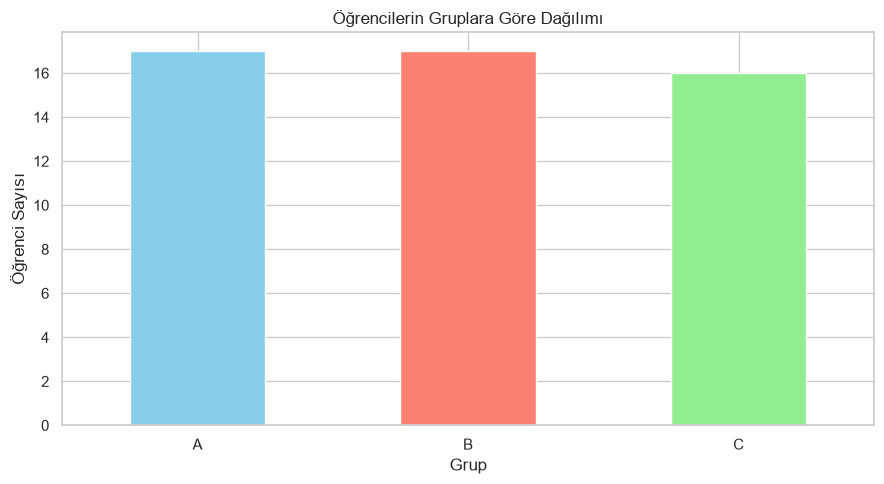

In [19]:
grup_sayilari = ogrenciler["Grup"].value_counts().sort_index()

print("Gruplara göre öğrenci sayıları:")
display(grup_sayilari.to_frame("Öğrenci Sayısı"))

ax = grup_sayilari.plot(kind="bar", color=["skyblue", "salmon", "lightgreen"])
ax.set_title("Öğrencilerin Gruplara Göre Dağılımı")
ax.set_xlabel("Grup")
ax.set_ylabel("Öğrenci Sayısı")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


### 4. Öğrencilerin gruplara dağılımı

In [20]:
# Sınav notlarını Min-Max yöntemiyle normalize edelim
sinav_min = sinav["Not"].min()
sinav_max = sinav["Not"].max()

if sinav_max == sinav_min:
    sinav["Not_Normalize"] = 0.0
else:
    sinav["Not_Normalize"] = (
        (sinav["Not"] - sinav_min) / (sinav_max - sinav_min)
    )

# Günlük değerlendirme puanlarını normalize edelim
puan_min = degerlendirme["Puan"].min()
puan_max = degerlendirme["Puan"].max()

if puan_max == puan_min:
    degerlendirme["Puan_Normalize"] = 0.0
else:
    degerlendirme["Puan_Normalize"] = (
        (degerlendirme["Puan"] - puan_min) / (puan_max - puan_min)
    )

print("Sınav normalizasyon aralığı:", sinav_min, "-", sinav_max)
print("Değerlendirme normalizasyon aralığı:", puan_min, "-", puan_max)

display(sinav.head())
display(degerlendirme.head())


Sınav normalizasyon aralığı: 0.0 - 100.0
Değerlendirme normalizasyon aralığı: 0 - 9


,Tarih,No,Not,Not_Normalize
0,2022-10-10,1,50.0,0.5
1,2022-10-10,2,100.0,1.0
2,2022-10-10,3,100.0,1.0
3,2022-10-10,4,100.0,1.0
4,2022-10-10,5,100.0,1.0


,Tarih,No,Puan,Puan_Normalize
0,2022-10-10,1,3,0.333333
1,2022-10-10,2,6,0.666667
2,2022-10-10,3,6,0.666667
3,2022-10-10,4,6,0.666667
4,2022-10-10,5,6,0.666667


### 5. Sınav ve değerlendirme verilerini normalize etme

In [21]:
# Sınav ve değerlendirme verilerini tarih ve öğrenci numarasına göre birleştirelim
basari = pd.merge(
    sinav,
    degerlendirme,
    on=["Tarih", "No"],
    how="inner",
    validate="one_to_one"
)

# Öğrenci adı ve grubunu ekleyelim
basari = pd.merge(
    basari,
    ogrenciler[["No", "Ad Soyad", "Grup"]],
    on="No",
    how="left",
    validate="many_to_one"
)

# Başarı puanı: %70 sınav + %30 günlük değerlendirme
basari["Basari_Puani"] = (
    basari["Not_Normalize"] * 0.7 +
    basari["Puan_Normalize"] * 0.3
)

display(basari.head(10))

print("Toplam başarı kaydı:", len(basari))
print("Başarı puanı en düşük:", basari["Basari_Puani"].min())
print("Başarı puanı en yüksek:", basari["Basari_Puani"].max())
print("Genel başarı ortalaması:", basari["Basari_Puani"].mean())


,Tarih,No,Not,Not_Normalize,Puan,Puan_Normalize,Ad Soyad,Grup,Basari_Puani
0,2022-10-10,1,50.00,0.5000,3,0.333333,Ahmet Yıldırım,A,0.450000
1,2022-10-10,2,100.00,1.0000,6,0.666667,Mehmet Demir,B,0.900000
2,2022-10-10,3,100.00,1.0000,6,0.666667,Ayşe Kaya,C,0.900000
3,2022-10-10,4,100.00,1.0000,6,0.666667,Fatma Şahin,A,0.900000
4,2022-10-10,5,100.00,1.0000,6,0.666667,Hasan Arslan,B,0.900000
5,2022-10-10,6,100.00,1.0000,6,0.666667,Hüseyin Yalçın,C,0.900000
6,2022-10-10,7,100.00,1.0000,6,0.666667,Zeynep Aydın,A,0.900000
7,2022-10-10,8,100.00,1.0000,6,0.666667,Emre Korkmaz,B,0.900000
8,2022-10-10,9,0.00,0.0000,0,0.000000,Elif Çetin,C,0.000000
9,2022-10-10,10,16.67,0.1667,1,0.111111,Murat Koç,A,0.150023


Toplam başarı kaydı: 650
Başarı puanı en düşük: 0.0
Başarı puanı en yüksek: 1.0
Genel başarı ortalaması: 0.6558708769230769


### 6. Verileri birleştirme ve başarı puanını hesaplama

En başarılı 5 öğrenci:


,No,Ad Soyad,Grup,Basari_Puani
41,42,Levent Güney,C,0.894872
16,17,Barış Kurt,B,0.894872
2,3,Ayşe Kaya,C,0.894872
3,4,Fatma Şahin,A,0.894872
39,40,Ahmetcan Karakaya,A,0.894872


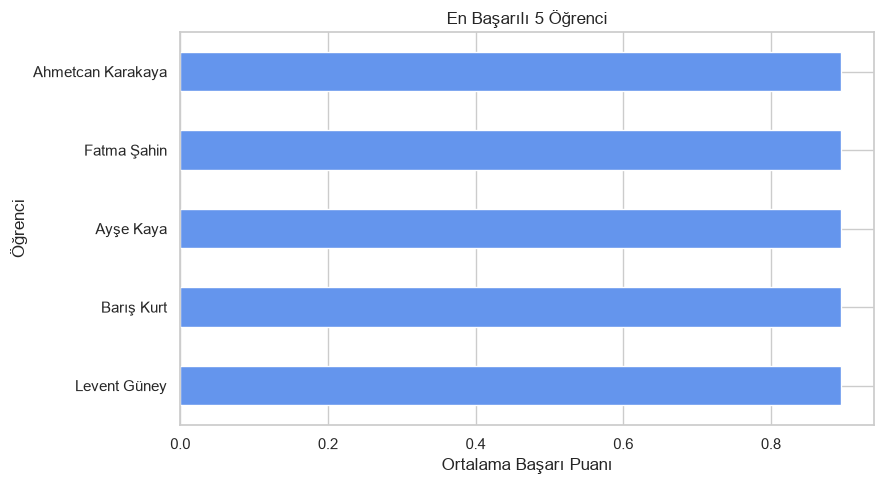

In [22]:
# Her öğrencinin 13 günlük başarı puanı ortalamasını hesaplayalım
ogrenci_basari = (
    basari.groupby(["No", "Ad Soyad", "Grup"])["Basari_Puani"]
    .mean()
    .reset_index()
    .sort_values("Basari_Puani", ascending=False)
)

# Ödevde N belirtilmediği için örnek olarak ilk 5 öğrenciyi gösteriyoruz
N = 5
en_basarili_ogrenciler = ogrenci_basari.head(N)

print(f"En başarılı {N} öğrenci:")
display(en_basarili_ogrenciler)

ax = en_basarili_ogrenciler.sort_values("Basari_Puani").plot(
    x="Ad Soyad", y="Basari_Puani", kind="barh", legend=False, color="cornflowerblue"
)
ax.set_title(f"En Başarılı {N} Öğrenci")
ax.set_xlabel("Ortalama Başarı Puanı")
ax.set_ylabel("Öğrenci")
plt.tight_layout()
plt.show()


### 7. Tüm tarihlere göre en başarılı 5 öğrenci

Grupların genel başarı ortalamaları:


,Ortalama Başarı Puanı
Grup,
B,0.674344
A,0.654059
C,0.638168


En başarılı grup: B


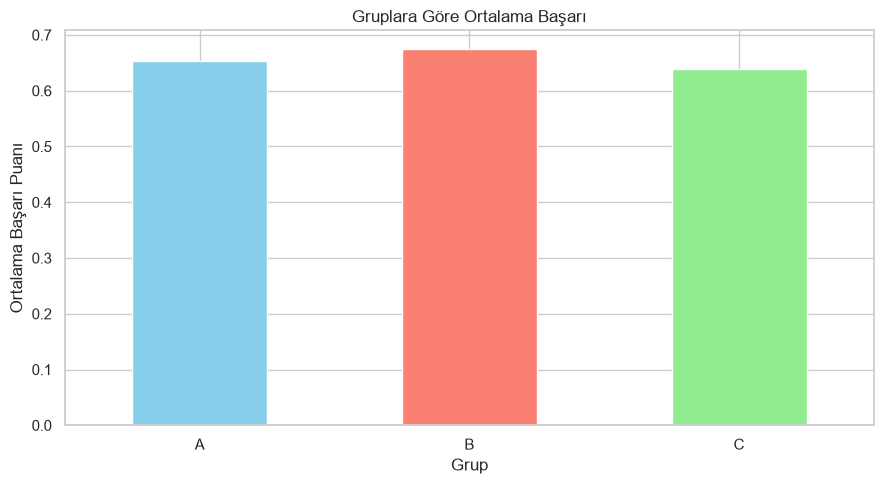

In [23]:
grup_basari = (
    basari.groupby("Grup")["Basari_Puani"]
    .mean()
    .sort_values(ascending=False)
)

print("Grupların genel başarı ortalamaları:")
display(grup_basari.to_frame("Ortalama Başarı Puanı"))

print("En başarılı grup:", grup_basari.idxmax())

ax = grup_basari.sort_index().plot(kind="bar", color=["skyblue", "salmon", "lightgreen"])
ax.set_title("Gruplara Göre Ortalama Başarı")
ax.set_xlabel("Grup")
ax.set_ylabel("Ortalama Başarı Puanı")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


### 8. En başarılı grubu bulma

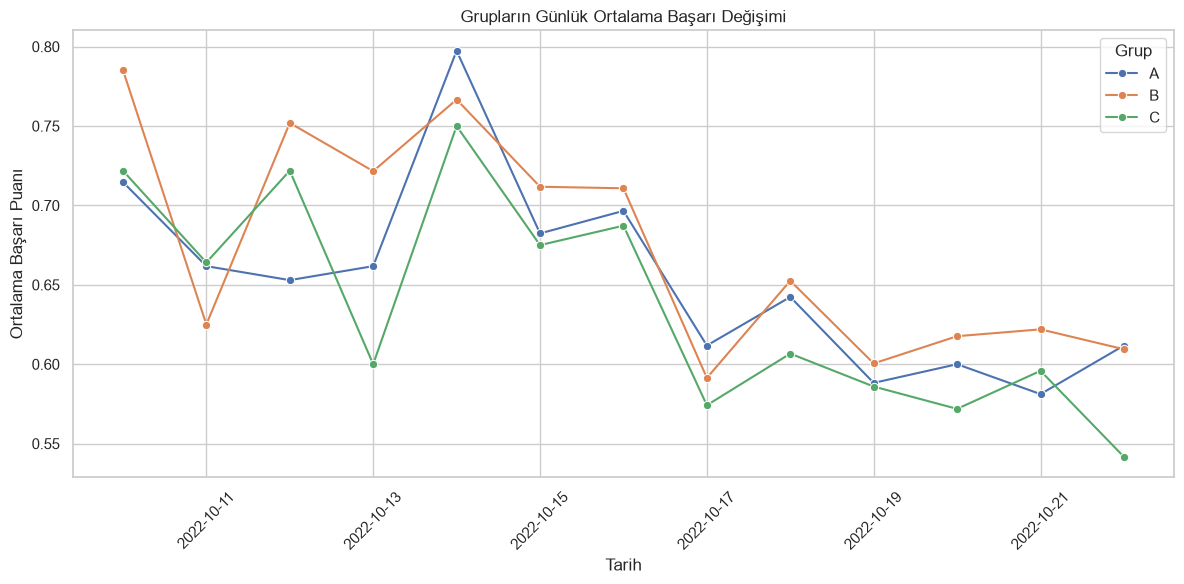

In [24]:
gunluk_grup_basari = (
    basari.groupby(["Tarih", "Grup"])["Basari_Puani"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=gunluk_grup_basari,
    x="Tarih",
    y="Basari_Puani",
    hue="Grup",
    marker="o"
)
plt.title("Grupların Günlük Ortalama Başarı Değişimi")
plt.xlabel("Tarih")
plt.ylabel("Ortalama Başarı Puanı")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 9. Grupların tarih aralığındaki günlük başarı grafiği

,Tarih,Sinav_Ortalamasi
0,2022-10-10,82.3332
1,2022-10-11,78.0000
2,2022-10-12,78.6662
3,2022-10-13,73.6666
4,2022-10-14,77.1114
5,2022-10-15,73.9998
6,2022-10-16,72.2500
7,2022-10-17,68.4000
8,2022-10-18,73.2000
9,2022-10-19,71.0000


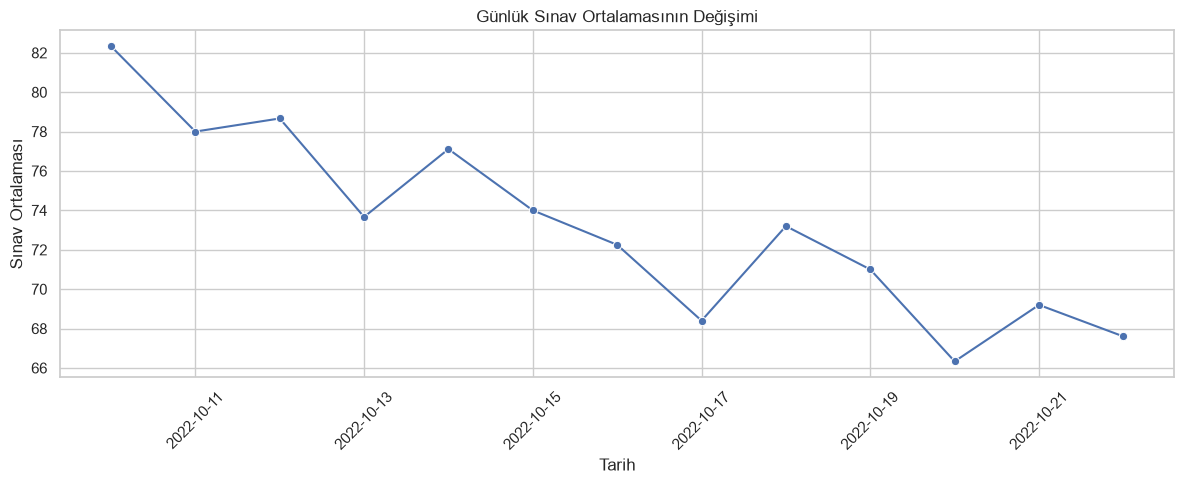

In [25]:
gunluk_sinav_ort = (
    sinav.groupby("Tarih")["Not"]
    .mean()
    .reset_index(name="Sinav_Ortalamasi")
)

display(gunluk_sinav_ort)

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=gunluk_sinav_ort,
    x="Tarih",
    y="Sinav_Ortalamasi",
    marker="o"
)
plt.title("Günlük Sınav Ortalamasının Değişimi")
plt.xlabel("Tarih")
plt.ylabel("Sınav Ortalaması")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 10. Günlük sınav ortalamasının değişimi

Tanımlayıcı istatistikler:


,Ortalama,Medyan,Mod,Standart Sapma
Sınav Notu,73.212323,100.0,100.0,39.873394
Değerlendirme Puanı,4.301538,5.0,5,2.628778
Başarı Puanı,0.655871,0.866667,0.0,0.359301


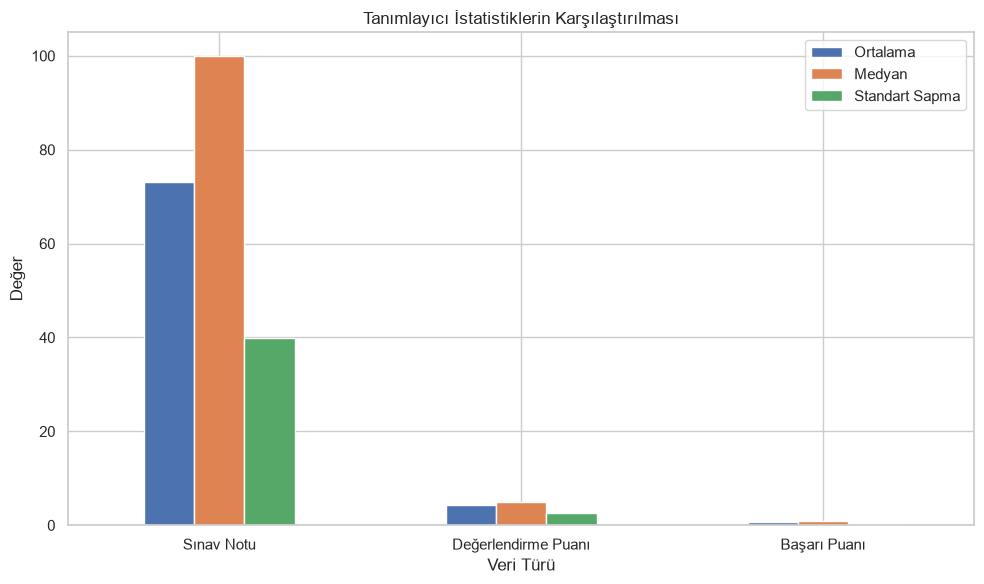

In [26]:
def tanimlayici_istatistik(veri, sutun):
    seri = veri[sutun].dropna()
    modlar = seri.mode().tolist()

    return pd.Series({
        "Ortalama": seri.mean(),
        "Medyan": seri.median(),
        "Mod": ", ".join(map(str, modlar)),
        "Standart Sapma": seri.std()
    })

istatistikler = pd.DataFrame({
    "Sınav Notu": tanimlayici_istatistik(sinav, "Not"),
    "Değerlendirme Puanı": tanimlayici_istatistik(degerlendirme, "Puan"),
    "Başarı Puanı": tanimlayici_istatistik(basari, "Basari_Puani")
}).T

print("Tanımlayıcı istatistikler:")
display(istatistikler.round(3))

# Ortalama, medyan ve standart sapmayı karşılaştıralım
istatistik_grafik = istatistikler[["Ortalama", "Medyan", "Standart Sapma"]].astype(float)
istatistik_grafik.plot(kind="bar", figsize=(10, 6))
plt.title("Tanımlayıcı İstatistiklerin Karşılaştırılması")
plt.ylabel("Değer")
plt.xlabel("Veri Türü")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### 11. Tanımlayıcı istatistikler

Sınav notu ile değerlendirme puanı arasındaki korelasyon: 0.890


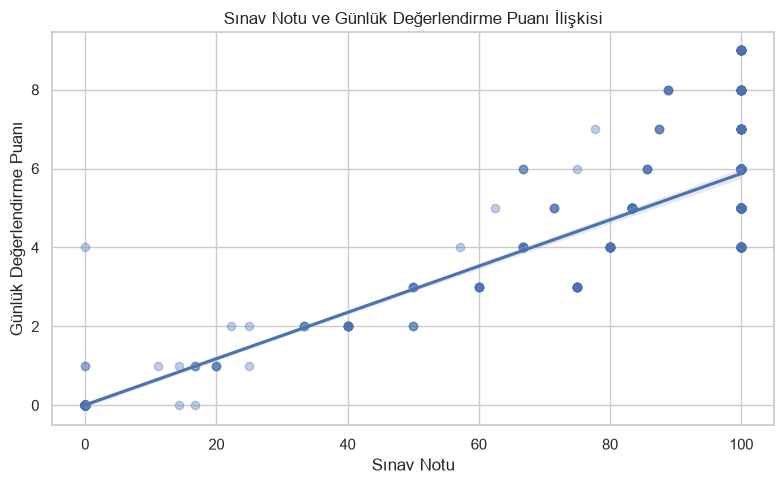

Yorum: İki değişken arasında pozitif yönlü ilişki vardır.
Not: Korelasyon ilişkiyi gösterir; tek başına neden-sonuç anlamına gelmez.


In [27]:
# Ham sınav notu ve ham değerlendirme puanı arasındaki Pearson korelasyonu
korelasyon = basari["Not"].corr(basari["Puan"])

print(f"Sınav notu ile değerlendirme puanı arasındaki korelasyon: {korelasyon:.3f}")

plt.figure(figsize=(8, 5))
sns.regplot(data=basari, x="Not", y="Puan", scatter_kws={"alpha": 0.35})
plt.title("Sınav Notu ve Günlük Değerlendirme Puanı İlişkisi")
plt.xlabel("Sınav Notu")
plt.ylabel("Günlük Değerlendirme Puanı")
plt.tight_layout()
plt.show()

if korelasyon > 0:
    print("Yorum: İki değişken arasında pozitif yönlü ilişki vardır.")
elif korelasyon < 0:
    print("Yorum: İki değişken arasında negatif yönlü ilişki vardır.")
else:
    print("Yorum: Doğrusal ilişki yoktur veya çok zayıftır.")

print("Not: Korelasyon ilişkiyi gösterir; tek başına neden-sonuç anlamına gelmez.")


### 12. Araştırma sorusu 1: Sınav notu ile günlük değerlendirme puanı ilişkili mi?

Grupların günlük başarı ortalamalarına göre standart sapmaları:


,Günlük Başarı Standart Sapması
Grup,
A,0.060021
C,0.068146
B,0.069065


En istikrarlı grup: A
Yorum: Günlük başarı ortalamalarının standart sapması en düşük olan grup, günler arasında daha istikrarlı performans göstermiştir.


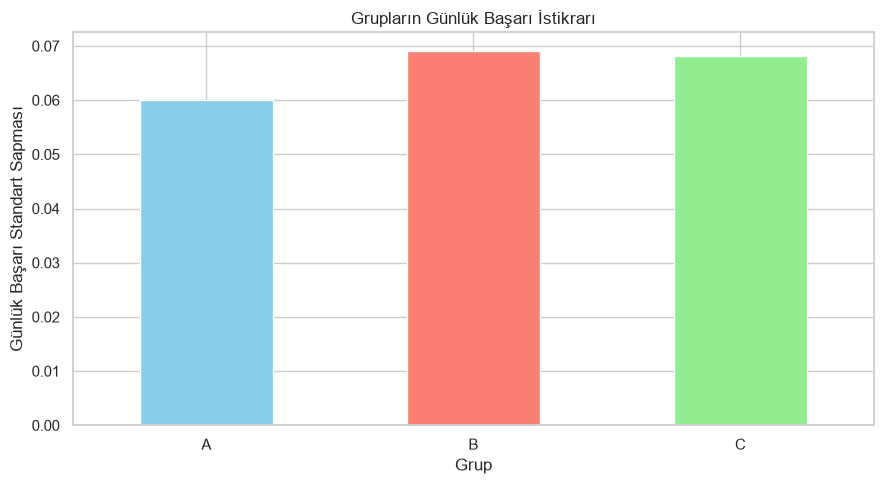

In [28]:
# Her grubun günlük başarı ortalamalarının standart sapmasını hesaplayalım
grup_istikrar = (
    gunluk_grup_basari.groupby("Grup")["Basari_Puani"]
    .std()
    .sort_values()
)

print("Grupların günlük başarı ortalamalarına göre standart sapmaları:")
display(grup_istikrar.to_frame("Günlük Başarı Standart Sapması"))

en_istikrarli_grup = grup_istikrar.idxmin()
print("En istikrarlı grup:", en_istikrarli_grup)
print("Yorum: Günlük başarı ortalamalarının standart sapması en düşük olan grup, günler arasında daha istikrarlı performans göstermiştir.")

ax = grup_istikrar.sort_index().plot(kind="bar", color=["skyblue", "salmon", "lightgreen"])
ax.set_title("Grupların Günlük Başarı İstikrarı")
ax.set_xlabel("Grup")
ax.set_ylabel("Günlük Başarı Standart Sapması")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


### 13. Araştırma sorusu 2: Hangi grup daha istikrarlı başarı gösteriyor?

In [29]:
print("GENEL DEĞERLENDİRME")
print("-------------------")
print(f"Analiz edilen öğrenci sayısı: {ogrenciler['No'].nunique()}")
print(f"Analiz edilen gün sayısı: {basari['Tarih'].nunique()}")
print(f"Genel ortalama başarı puanı: {basari['Basari_Puani'].mean():.3f}")
print(f"En başarılı grup: {grup_basari.idxmax()}")
print(f"En istikrarlı grup: {en_istikrarli_grup}")
print(f"En başarılı öğrenci: {ogrenci_basari.iloc[0]['Ad Soyad']}")


GENEL DEĞERLENDİRME
-------------------
Analiz edilen öğrenci sayısı: 50
Analiz edilen gün sayısı: 13
Genel ortalama başarı puanı: 0.656
En başarılı grup: B
En istikrarlı grup: A
En başarılı öğrenci: Levent Güney
